In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fixa a semente de números aleatórios para que os resultados sejam sempre os mesmos
np.random.seed(123)
# Define o "tempo" de 1 a 100
tempo = np.arange(1, 101)

In [ ]:
# --- 1. Série Estacionária ---
# Gera 100 números aleatórios de uma distribuição normal
# loc =(média) = 10
# scale = desvio padrão) = 2
# size = (quantidade) = 100
estacionaria = np.random.normal(loc=10, scale=2, size=100)
# Calcula a média e o desvio padrão da série
media_est = np.mean(estacionaria)
dp_est = np.std(estacionaria) # Desvio padrão (medida de dispersão)

In [ ]:
# --- 2. Série Não Estacionária (com tendência) ---
passos_aleatorios = np.random.normal(loc=0.5, scale=2, size=100)
# soma acumulada ("cumsum") para criar a tendência
nao_estacionaria = np.cumsum(passos_aleatorios)
# Calcula a média e o desvio padrão da nova série
media_nao_est = np.mean(nao_estacionaria)
dp_nao_est = np.std(nao_estacionaria)

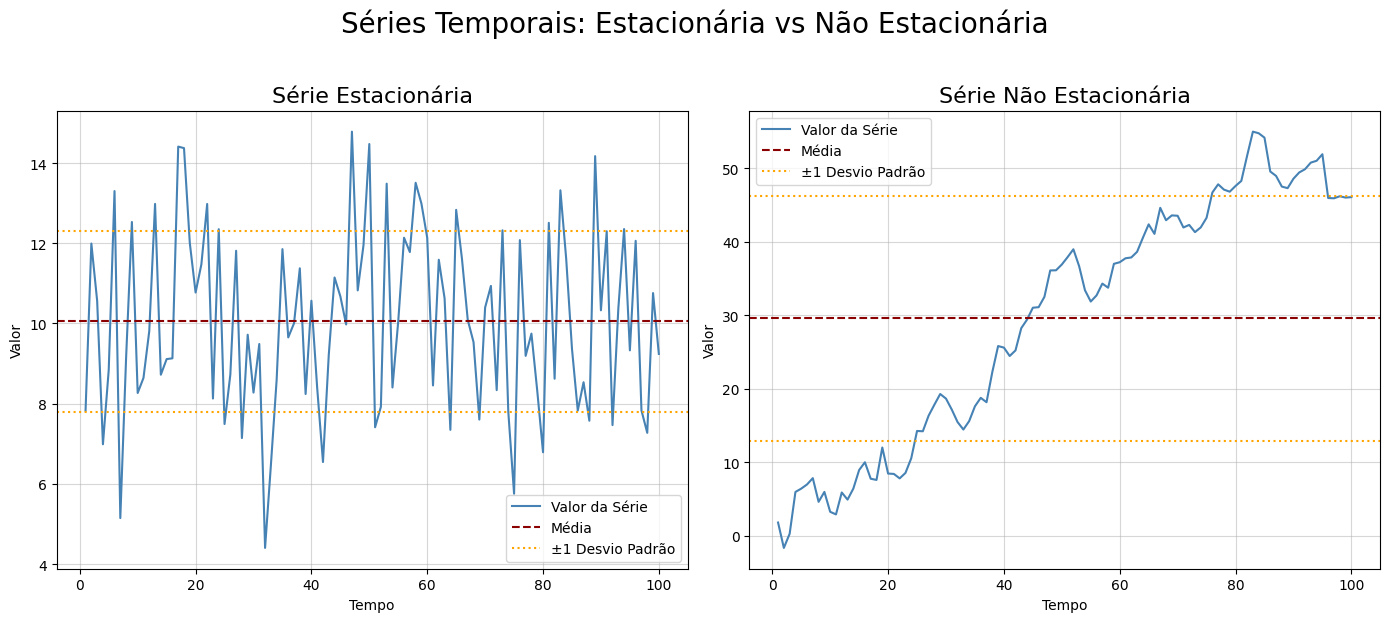

In [ ]:

# figura e dois "eixos" (subplots) lado a lado (1 linha, 2 colunas)
# - fig: é a figura inteira (a "janela" do gráfico)
# - (ax1, ax2): são os dois gráficos, um para cada série.
# - figsize: define um bom tamanho para a figura
#   sharey permite que o eixo Y de cada gráfico tenha sua própria escala.
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), sharey=False) # --- Gráfico 1: Estacionária (no eixo ax1) ---
ax1.plot(tempo, estacionaria, color="steelblue", label="Valor da Série")
ax1.set_title("Série Estacionária", fontsize=16)
ax1.set_xlabel("Tempo")
ax1.set_ylabel("Valor")
# Adiciona as linhas de média e desvio padrão
ax1.axhline(media_est, color="darkred", linestyle="--", label="Média")
ax1.axhline(media_est + dp_est, color="orange", linestyle=":", label="±1 Desvio Padrão")
ax1.axhline(media_est - dp_est, color="orange", linestyle=":")
ax1.legend() # Mostra a legenda
ax1.grid(True, alpha=0.5) # Adiciona uma grade suave
# --- Gráfico 2: Não Estacionária (no eixo ax2) ---
ax2.plot(tempo, nao_estacionaria, color="steelblue", label="Valor da Série")
ax2.set_title("Série Não Estacionária", fontsize=16)
ax2.set_xlabel("Tempo")
ax2.set_ylabel("Valor")
#  linhas de média e desvio padrão
ax2.axhline(media_nao_est, color="darkred", linestyle="--", label="Média")
ax2.axhline(media_nao_est + dp_nao_est, color="orange", linestyle=":", label="±1 Desvio Padrão")
ax2.axhline(media_nao_est - dp_nao_est, color="orange", linestyle=":")
ax2.legend()
ax2.grid(True, alpha=0.5)
fig.suptitle("Séries Temporais: Estacionária vs Não Estacionária", fontsize=20, y=1.03)
plt.tight_layout()
plt.show()

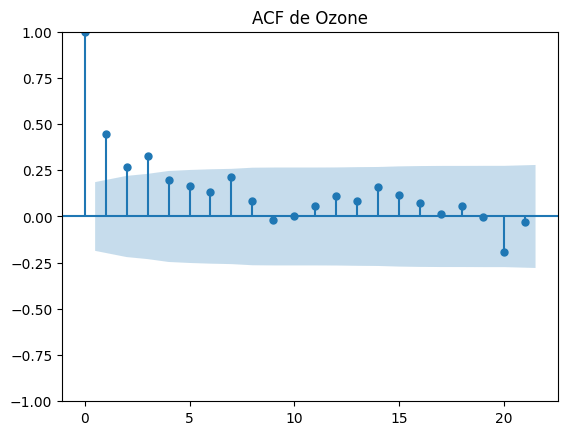

In [ ]:
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt
import pandas as pd
airquality_df = sm.datasets.get_rdataset("airquality", "datasets").data
dados = airquality_df.dropna()
plot_acf(dados['Ozone'], title="ACF de Ozonio")
plt.show()

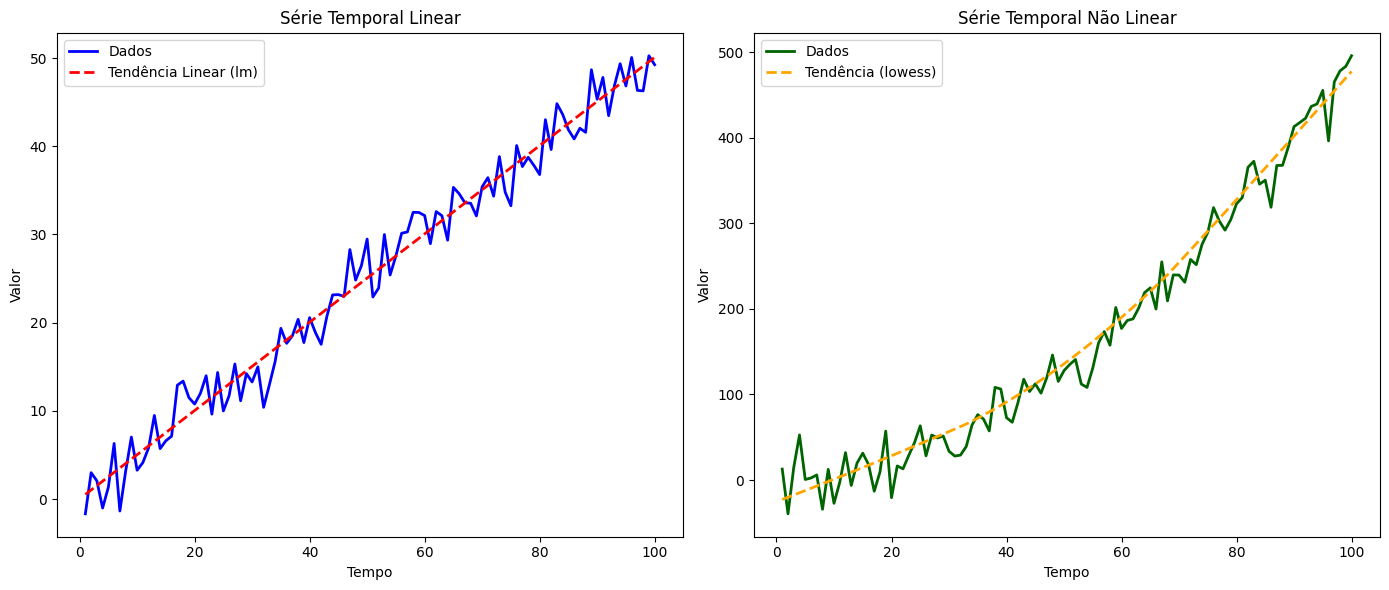

In [ ]:
# pip install numpy matplotlib scipy statsmodels
import numpy as np
import matplotlib.pyplot as plt
# 'linregress' para fazer a regressão linear
from scipy.stats import linregress
# 'lowess' para a suavização não-linear
from statsmodels.nonparametric.smoothers_lowess import lowess
# --- 1. Configuração e Criação dos Dados ---
np.random.seed(123)
# Período de tempo (tempo <- 1:100)
tempo = np.arange(1, 101)
# Série linear: y = a*t + erro (rnorm)
erro_linear = np.random.normal(loc=0, scale=2, size=100)
serie_linear = 0.5 * tempo + erro_linear
# Série não linear: y = a*t^2 + erro
erro_nao_linear = np.random.normal(loc=0, scale=20, size=100)
serie_nao_linear = 0.05 * (tempo**2) + erro_nao_linear
# --- 2. Criar os gráficos lado a lado ---
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))
# --- 3. Gráfico da série linear (no eixo ax1) ---
# Plot da série (type="l" é o padrão, col="blue" é color="blue")
ax1.plot(tempo, serie_linear, color="blue", linewidth=2, label="Dados")
ax1.set_title("Série Temporal Linear") # main=
ax1.set_xlabel("Tempo") # xlab=
ax1.set_ylabel("Valor") # ylab=
# Adicionar a Regressão linear
slope, intercept, r_value, p_value, std_err = linregress(tempo, serie_linear)
# 2. Criamos os valores Y da linha de regressão (y = a*x + b)
linha_regressao = slope * tempo + intercept
ax1.plot(tempo, linha_regressao, color="red", linestyle="--", linewidth=2, label="Tendência Linear (lm)")
ax1.legend()
# --- 4. Gráfico da série não linear (no eixo ax2) ---
ax2.plot(tempo, serie_nao_linear, color="darkgreen", linewidth=2, label="Dados")
ax2.set_title("Série Temporal Não Linear")
ax2.set_xlabel("Tempo")
ax2.set_ylabel("Valor")
# Adicionar a Suavização local (lines(lowess(...)))
# 1. Calculamos a suavização lowess
suavizacao = lowess(serie_nao_linear, tempo)
# 2. 'suavizacao' é um array com 2 colunas (x, y). a coluna 0 (x) e a coluna 1 (y) para plotar
ax2.plot(suavizacao[:, 0], suavizacao[:, 1], color="orange", linestyle="--", linewidth=2, label="Tendência (lowess)")
ax2.legend()
plt.tight_layout()
plt.show()

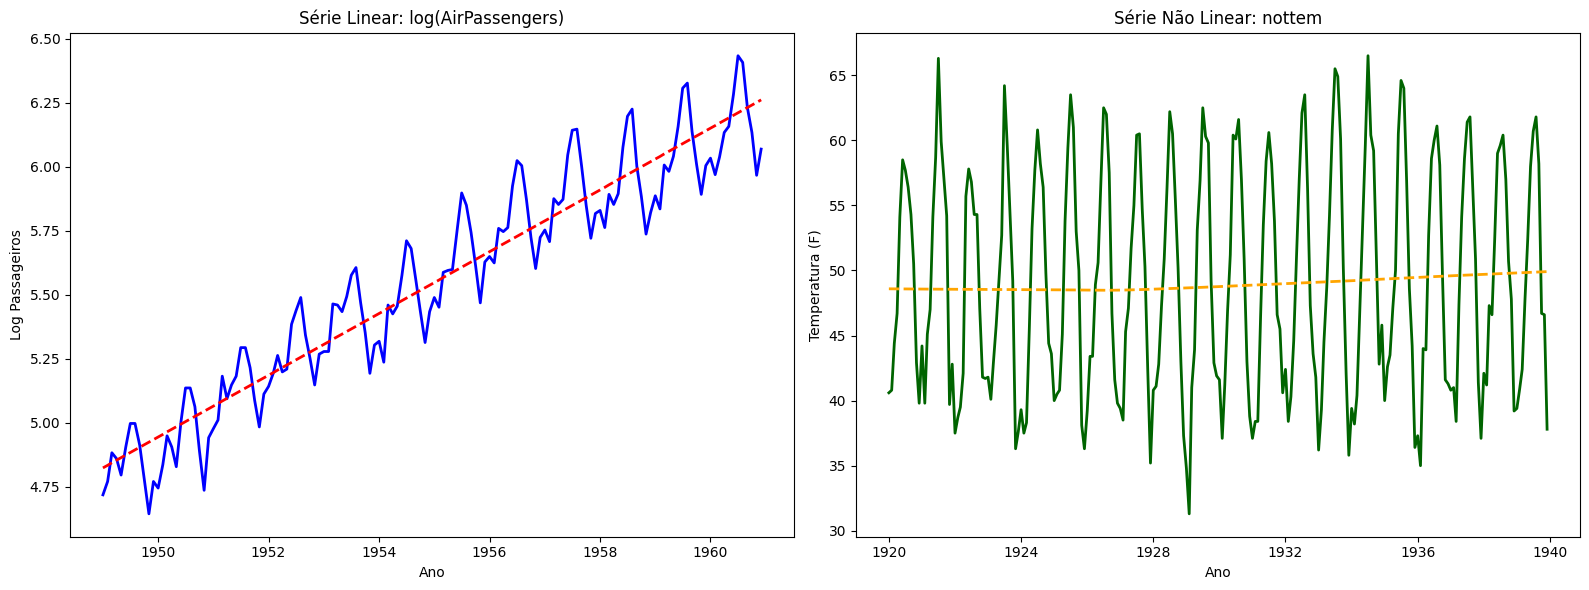

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm
url_air = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
air_passengers = pd.read_csv(url_air, parse_dates=['Month'], index_col='Month')
# Série aproximadamente linear (com log)
# O log é aplicado para linearizar a tendência (que é multiplicativa)
log_air = np.log(air_passengers['Passengers'])
# 2. Nottem (do statsmodels)
# Esta é a série de temperaturas de Nottingham, já vem no statsmodels
nottem_data = sm.datasets.get_rdataset("nottem", "datasets").data
#  criar um índice de datas(1920-1939, mensal) para o nosso DataFrame pandas.
nottem_index = pd.date_range(start='1920-01-01', periods=len(nottem_data), freq='MS')
nottem = pd.Series(nottem_data['value'].values, index=nottem_index)
# 1. PLOTAR AS DUAS SÉRIES LADO A LADO
# Layout horizontal (1 linha, 2 colunas) -> plt.subplots(1, 2)
fig1, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
# --- Gráfico 1: Série Linear (log_air) ---
ax1.plot(log_air.index, log_air, color="blue", linewidth=2)
ax1.set_xlabel("Ano")
ax1.set_ylabel("Log Passageiros")
ax1.set_title("Série Linear: log(AirPassengers)")
# Adicionar regressão linear
# 1.  um eixo 'x' numérico para a regressão
tempo_air = np.arange(len(log_air))
# 2.  a regressão
slope, intercept, r, p, std_err = linregress(tempo_air, log_air)
# 3.  a linha de tendência
linha_regressao = (slope * tempo_air) + intercept
ax1.plot(log_air.index, linha_regressao, color="red", linestyle="--", linewidth=2)
# --- Gráfico 2: Série Não Linear (nottem) ---
ax2.plot(nottem.index, nottem, color="darkgreen", linewidth=2)
ax2.set_xlabel("Ano")
ax2.set_ylabel("Temperatura (F)")
ax2.set_title("Série Não Linear: nottem")
# Adicionar suavização
# 1. Criamos um eixo 'x' numérico para o lowess
tempo_nottem = np.arange(len(nottem))
suavizacao = lowess(nottem, tempo_nottem)
ax2.plot(nottem.index, suavizacao[:, 1], color="orange", linestyle="--", linewidth=2)
plt.tight_layout()
plt.show()

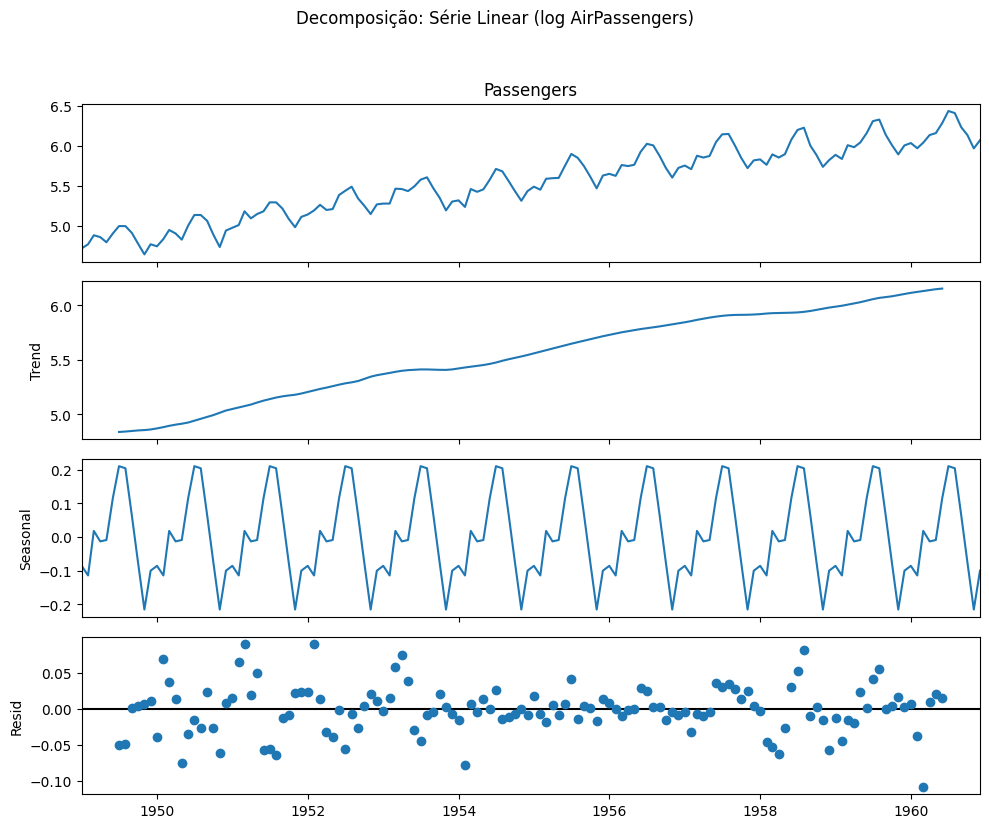

In [ ]:
# 2. DECOMPOSIÇÕES
# --- Decomposição da série linear (log_air) ---
#  'additive' (aditiva) porque aplicamos o log.
decomp_linear = seasonal_decompose(log_air, model='additive', period=12)
# O .plot() já cria a figura com os 4 gráficos (Original, Tendência, Sazonalidade, Resíduo)
fig_linear = decomp_linear.plot()
fig_linear.set_size_inches(10, 8) # Ajusta o tamanho da figura
fig_linear.suptitle("Decomposição: Série Linear (log AirPassengers)", y=1.03)
plt.tight_layout() # Ajusta para não sobrepor
plt.show()

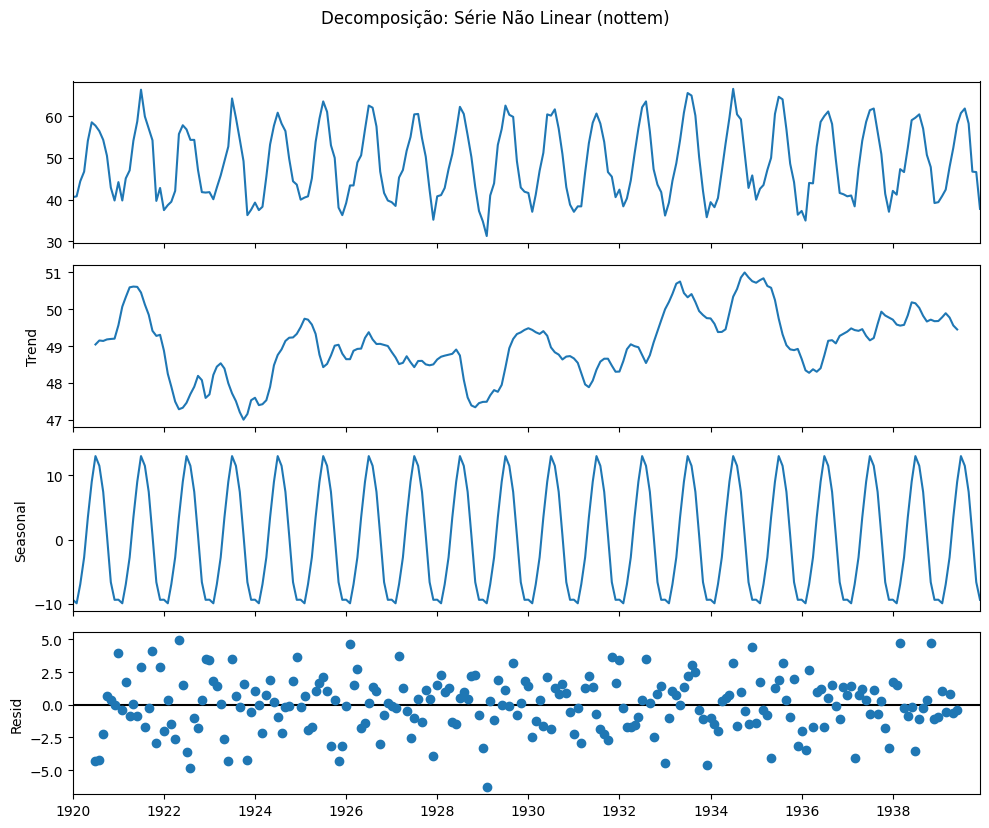

In [ ]:
# --- Decomposição da série não linear (nottem) ---
# A temperatura também segue um modelo aditivo (Temp = Tendência + Sazonalidade + Resíduo)
decomp_nao_linear = seasonal_decompose(nottem, model='additive', period=12)
fig_nao_linear = decomp_nao_linear.plot()
fig_nao_linear.set_size_inches(10, 8)
fig_nao_linear.suptitle("Decomposição: Série Não Linear (nottem)", y=1.03)
plt.tight_layout()
plt.show()

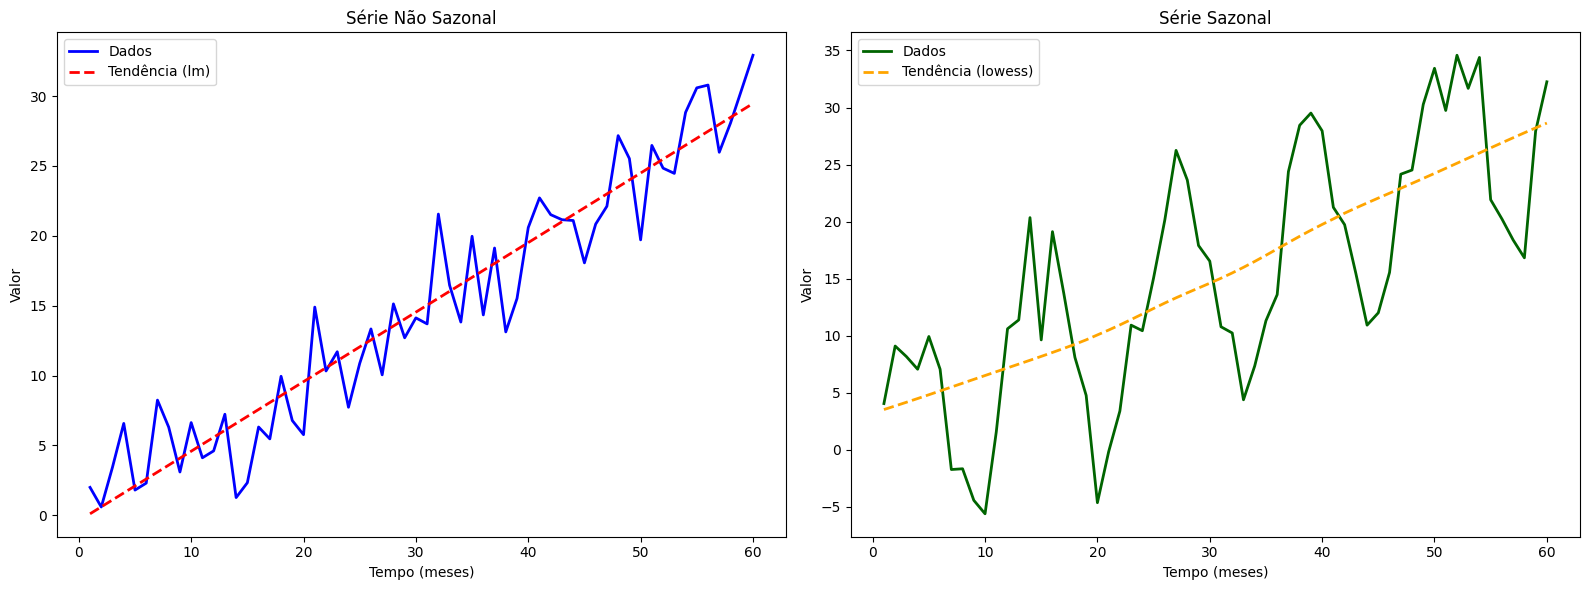

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from statsmodels.nonparametric.smoothers_lowess import lowess
# --- 1. Configuração e Criação dos Dados ---
np.random.seed(42)
# Criar sequência de tempo (ex: 5 anos mensais)
tempo = np.arange(1, 61) # 60 meses = 5 anos
# --- Série não sazonal: tendência + ruído ---
ruido_1 = np.random.normal(loc=0, scale=3, size=60)
serie_nao_sazonal = 0.5 * tempo + ruido_1
# --- Série sazonal: tendência + padrão cíclico + ruído ---
sazonalidade = 10 * np.sin(2 * np.pi * tempo / 12) # ciclo anual (12 meses)
ruido_2 = np.random.normal(loc=0, scale=3, size=60)
serie_sazonal = 0.5 * tempo + sazonalidade + ruido_2
# --- 2. Gráficos lado a lado ---
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
# --- 3. Gráfico da série não sazonal (no eixo ax1) ---
ax1.plot(tempo, serie_nao_sazonal, color="blue", linewidth=2, label="Dados")
ax1.set_title("Série Não Sazonal")
ax1.set_xlabel("Tempo (meses)")
ax1.set_ylabel("Valor")
# Adicionar regressão linear
slope, intercept, r, p, std_err = linregress(tempo, serie_nao_sazonal)
linha_regressao = slope * tempo + intercept
ax1.plot(tempo, linha_regressao, color="red", linestyle="--", linewidth=2, label="Tendência (lm)")
ax1.legend()
# --- 4. Gráfico da série sazonal (no eixo ax2) ---
ax2.plot(tempo, serie_sazonal, color="darkgreen", linewidth=2, label="Dados")
ax2.set_title("Série Sazonal")
ax2.set_xlabel("Tempo (meses)")
ax2.set_ylabel("Valor")
# Adicionar suavização
suavizacao = lowess(serie_sazonal, tempo)
ax2.plot(suavizacao[:, 0], suavizacao[:, 1], color="orange", linestyle="--", linewidth=2, label="Tendência (lowess)")
ax2.legend()
plt.tight_layout()
plt.show()

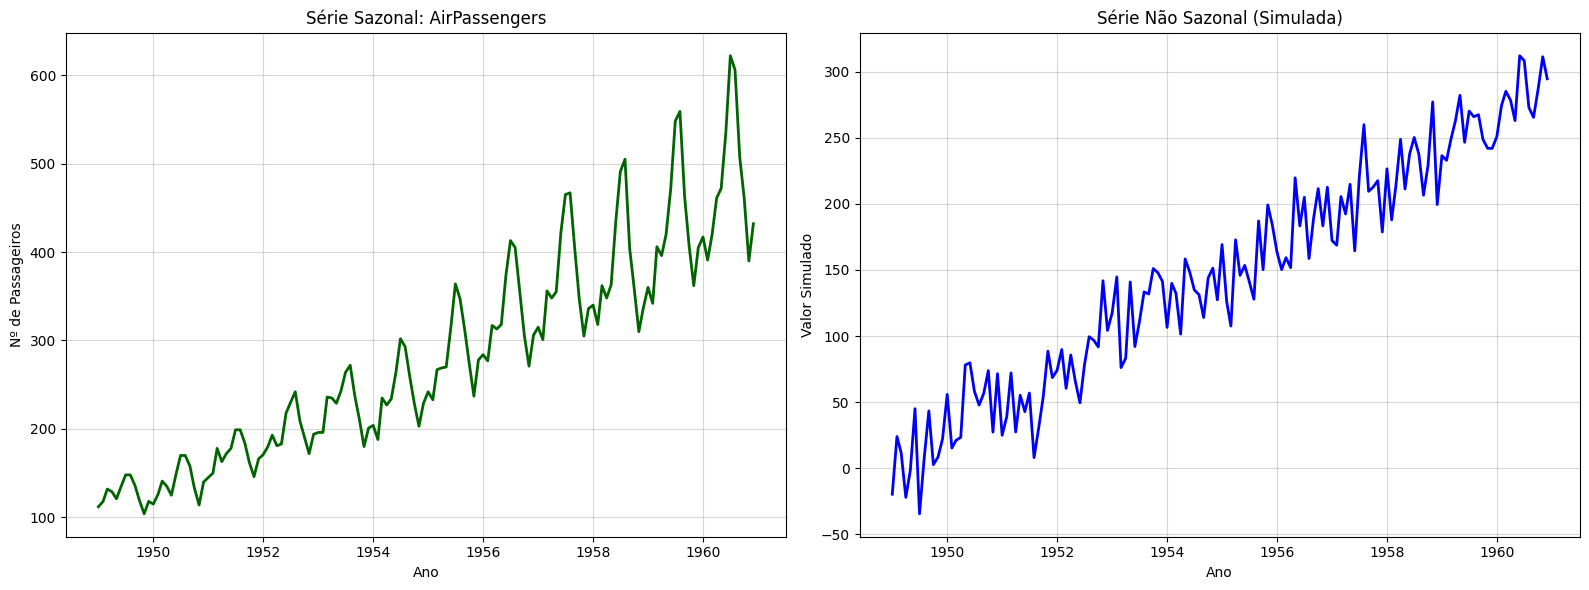

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# --- Carregar a base AirPassengers (da web) ---
url_air = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
air_passengers_df = pd.read_csv(url_air, parse_dates=['Month'], index_col='Month')
air_passengers = air_passengers_df['Passengers']
np.random.seed(123)
n_pontos = len(air_passengers)
tempo = np.arange(1, n_pontos + 1)
ruido = np.random.normal(loc=0, scale=20, size=n_pontos)
serie_nao_sazonal_array = 2 * tempo + ruido
ts_nao_sazonal = pd.Series(serie_nao_sazonal_array, index=air_passengers.index)
# --- Gráficos lado a lado: Sazonal x Não Sazonal ---
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
# --- Gráfico 1: Série Sazonal (ax1) ---
ax1.plot(air_passengers.index, air_passengers, color="darkgreen", linewidth=2)
ax1.set_title("Série Sazonal: AirPassengers")
ax1.set_xlabel("Ano")
ax1.set_ylabel("Nº de Passageiros")
ax1.grid(True, alpha=0.5)
# --- Gráfico 2: Série Não Sazonal (ax2) ---
ax2.plot(ts_nao_sazonal.index, ts_nao_sazonal, color="blue", linewidth=2)
ax2.set_title("Série Não Sazonal (Simulada)")
ax2.set_xlabel("Ano")
ax2.set_ylabel("Valor Simulado")
ax2.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Exibindo o gráfico de decomposição...


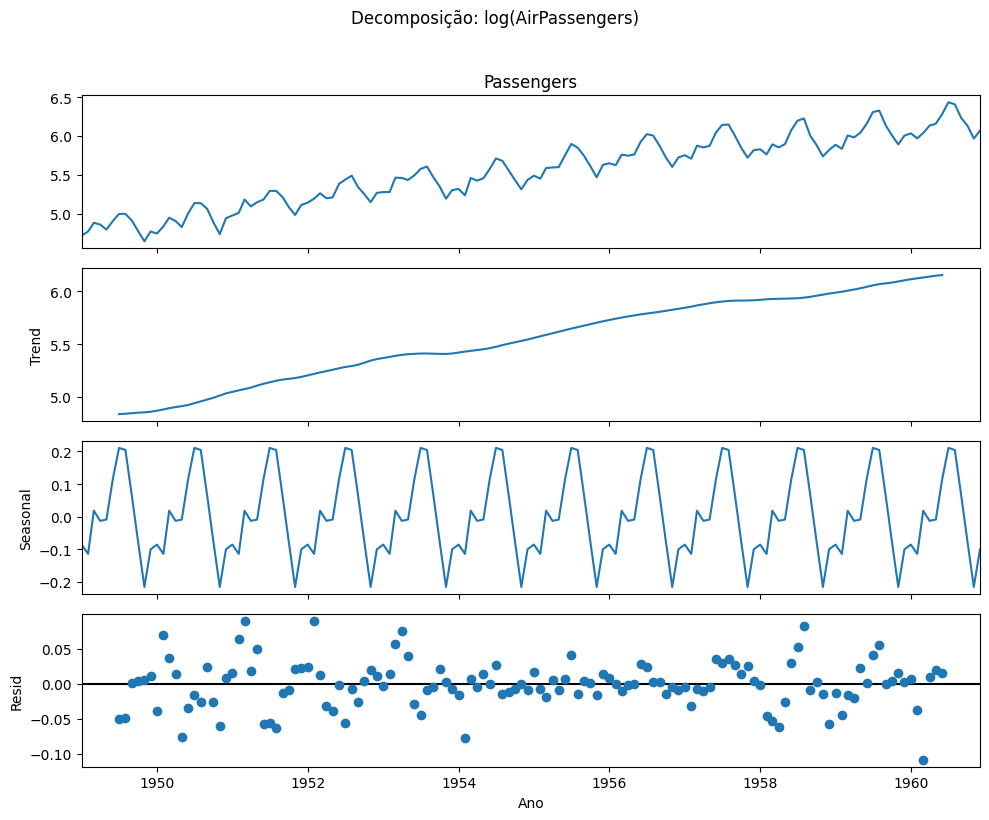

In [ ]:
# --- Decomposição da série AirPassengers (aditiva) ---
# Como AirPassengers tem crescimento exponencial, aplicamos log
log_air = np.log(air_passengers)
decomp = seasonal_decompose(log_air, model='additive', period=12)
print("Exibindo o gráfico de decomposição...")
fig = decomp.plot()
fig.set_size_inches(10, 8)
fig.suptitle("Decomposição: log(AirPassengers)", y=1.02)
for ax in fig.axes:
    ax.set_xlabel('') # Remove o xlab de todos
fig.axes[-1].set_xlabel("Ano")
plt.tight_layout()
plt.show()

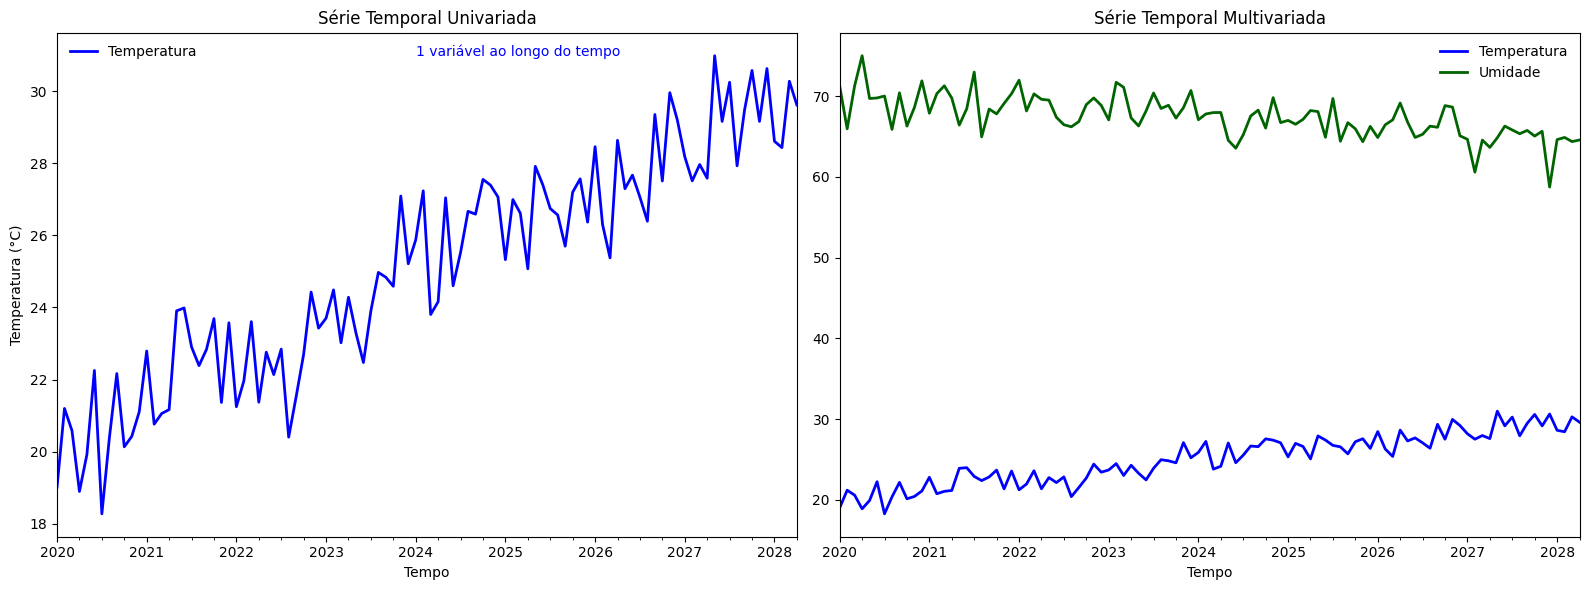

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# --- 1. Preparação ---
np.random.seed(123)
tempo_array = np.arange(1, 101) # 100 pontos
# --- 2. Série Univariada: exemplo de temperatura ---
ruido_temp = np.random.normal(loc=0, scale=1, size=100)
temperatura_array = 20 + 0.1 * tempo_array + ruido_temp
datas = pd.date_range(start='2020-01-01', periods=100, freq='MS')
# Criamos a Série (univariada)
ts_temperatura = pd.Series(temperatura_array, index=datas, name="Temperatura")
# --- 3. Série Multivariada: temperatura e umidade ---
ruido_umid = np.random.normal(loc=0, scale=2, size=100)
umidade_array = 70 - 0.05 * tempo_array + ruido_umid
ts_multi = pd.DataFrame({
    'Temperatura': temperatura_array,
    'Umidade': umidade_array
}, index=datas)
# --- 4. Gráficos lado a lado ---
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
# --- Gráfico 1: Série Univariada (ax1) ---
ts_temperatura.plot(ax=ax1, color="blue", linewidth=2)
ax1.set_title("Série Temporal Univariada")
ax1.set_ylabel("Temperatura (°C)")
ax1.set_xlabel("Tempo")
ax1.legend(loc="upper left", frameon=False)
ax1.text(pd.Timestamp('2024-01-01'), ts_temperatura.max(),
         "1 variável ao longo do tempo",
         color="blue")
# --- Gráfico 2: Série Multivariada (ax2) ---
ts_multi.plot(ax=ax2, color=["blue", "darkgreen"], linewidth=2)
ax2.set_title("Série Temporal Multivariada")
ax2.set_xlabel("Tempo")
ax2.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

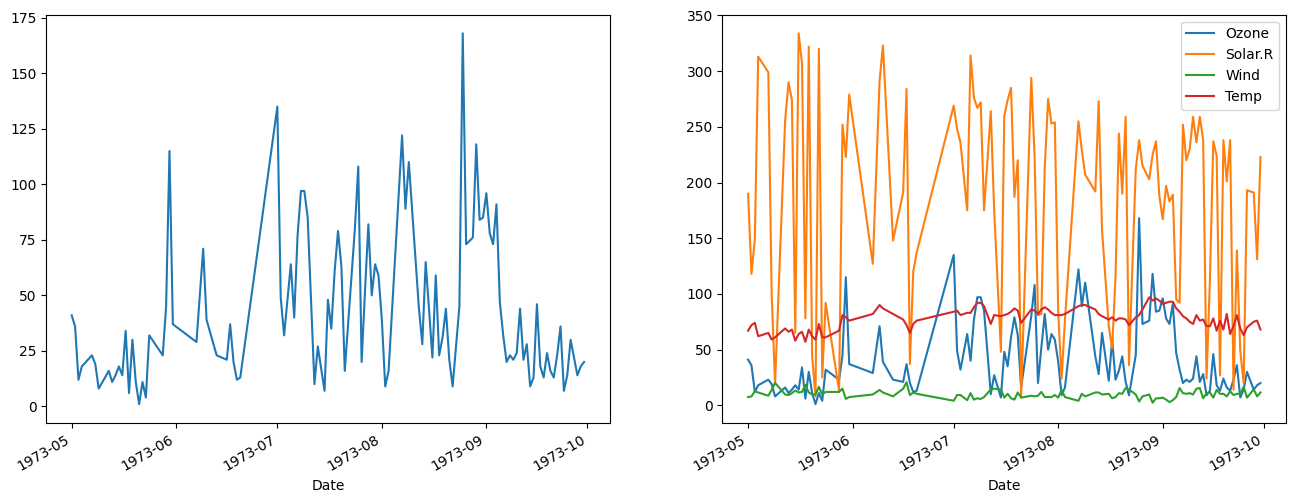

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
airquality_df = sm.datasets.get_rdataset("airquality", "datasets").data
dados = airquality_df.dropna().copy()
#criar uma coluna 'Date'combinando as colunas 'Month' e 'Day' com o ano de 1973.
dados['Date'] = pd.to_datetime(dados.assign(Year=1973)[['Year', 'Month', 'Day']])
# Agora, definimos essa coluna 'Date' como o índice do nosso DataFrame.
dados = dados.set_index('Date')
# --- 3. Criar série univariada (apenas Ozone) ---
ozone_ts = dados['Ozone']
# --- 4. Criar série multivariada com 4 variáveis ---
multi_ts = dados[['Ozone', 'Solar.R', 'Wind', 'Temp']]
# --- 5. Gráficos lado a lado ---
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
ozone_ts.plot(ax=ax1)
multi_ts.plot(ax=ax2)
plt.show()